# Tuần 12 — Phân tích Nhân quả (1/2): Kết quả tiềm năng và tác động trung bình

**UET.MAT1052 — Xác suất thống kê**

ThS. Hoàng Hữu Bách — BM. Khoa học & Kỹ thuật tính toán - Khoa Công nghệ Thông tin, VNU-UET

### Câu hỏi của buổi

Ở bệnh viện A, nhóm bệnh nhân dùng thuốc hạ huyết áp cũ có huyết áp tâm thu trung bình 145 mmHg; nhóm dùng thuốc mới có 128 mmHg.

Chênh lệch 17 mmHg là do thuốc mới tốt hơn, do bác sĩ kê thuốc mới cho những người vốn nhẹ bệnh hơn, hay một phần do cả hai? Tuần 10–11 cho biết một chênh lệch có "có ý nghĩa thống kê" hay không. Tuần này hỏi một câu khác: chênh lệch ấy có phải **tác động** của thuốc không, và cần những gì để trả lời.

### Sau buổi này, bạn làm được

- phân biệt một liên hệ quan sát được với tác động của một can thiệp;
- định nghĩa kết quả tiềm năng $Y(1)$, $Y(0)$, kết quả phản thực và tác động cá nhân; giải thích vì sao tác động cá nhân không quan sát được;
- tính ATE, ATT, ATC từ một bảng kết quả tiềm năng và diễn giải đúng mức “trung bình”;
- phát biểu ba giả định SUTVA, ignorability, positivity, cho ví dụ thỏa và vi phạm;
- so sánh trong từng tầng rồi chuẩn hóa để xử lý một biến gây nhiễu đã đo;
- giải thích bằng mô phỏng vì sao gán ngẫu nhiên giúp ước lượng không chệch.

Nội dung đáp ứng **LLO12.1/CLO4** của đề cương.

### Cần nhớ từ các buổi trước

- **Tương quan không phải nhân quả** (Tuần 04). Hai biến cùng tăng có thể do một biến thứ ba.
- **Kỳ vọng có điều kiện và kỳ vọng toàn phần** (Tuần 05–07). $E(Y)=P(A)\, E(Y\mid A)+P(\overline A)\, E(Y\mid\overline A)$.
- **Độc lập** (Tuần 05). $A$ và $B$ độc lập khi $P(A\mid B)=P(A)$: biết $B$ không đổi gì về $A$.
- **Kiểm định không cho biết nguyên nhân** (Tuần 10–11). Bác bỏ $H_0$ chỉ cho biết hai nhóm khác nhau, không cho biết vì sao.
- **Ví dụ Kristen Gilbert** (Tuần 10). Dữ liệu quan sát cho liên hệ rất mạnh nhưng không đủ để kết luận gây ra.

### Cách học notebook này

1. **Đọc** tình huống và phần giải tay.
2. **Đoán** kết quả trước khi chạy ô code hay mở đáp án.
3. **Chạy** ô bằng `Shift + Enter`.
4. **So sánh** kết quả với dự đoán; nếu khác, tìm xem mình đã hiểu sai ở bước nào.

Khối **Vì sao?** chứa chứng minh, có thể đọc sau. Ô có chú thích **Thử đổi** là chỗ bạn sửa tham số rồi chạy lại. Tên Ví dụ, Bài và Câu hỏi giữ đúng như slide để tiện đối chiếu.

**Thực hành vẽ:** [hướng dẫn Plotnine](./HUONG_DAN_PLOT.md). Mỗi hình có một đoạn “Đọc code vẽ” giải thích đúng các lệnh dùng ở hình đó, và một đoạn “Đọc hình” chỉ ra cần nhìn vào đâu.

## Lộ trình học

| Cách học | Nội dung cần làm |
|---|---|
| Học trên lớp | Mục 1–5: tương quan và nhân quả, kết quả tiềm năng, ATE/ATT/ATC, ba giả định, chuẩn hóa theo tầng. |
| Tự luyện | Ví dụ 1–4, Câu hỏi 1–2, Bài tập 1–2; tự đổi cơ cấu tầng ở ô “Thử đổi” của Bài tập 1. |
| Đọc sâu | Mục 6 (bổ sung theo đề cương): mô phỏng gán ngẫu nhiên; các khối **Vì sao?**: phân rã hiệu thô, công thức chuẩn hóa. |

Chạy từ đầu bằng **Restart Kernel and Run All Cells** trước khi học, để mọi bảng và hình khớp với chữ trong bài.

### Đi đến các phần

[1. Cùng một chênh lệch có nhiều cơ chế](#muc-1) · [2. Một cá thể, hai kết quả tiềm năng nhưng chỉ một kết quả quan sát](#muc-2) · [3. ATE, ATT, ATC nhắm tới nhóm nào?](#muc-3) · [4. Ba giả định nối dữ liệu với câu hỏi phản thực](#muc-4) · [5. So trong tầng rồi chuẩn hóa theo đúng tổng thể](#muc-5) · [6. Bổ sung theo đề cương: vì sao gán ngẫu nhiên giúp ích?](#muc-6)

## Ký hiệu dùng trong buổi này

| Ký hiệu | Đọc là | Nghĩa | Ví dụ trong bài |
|---|---|---|---|
| $Z_i$ | Z i | can thiệp mà cá thể $i$ thực nhận: 1 = mới, 0 = cũ | $Z_X=1$ |
| $Y_i(1)$, $Y_i(0)$ | Y i của một, Y i của không | kết quả của **cùng** cá thể $i$ nếu nhận can thiệp mới / nếu nhận đối chứng | $Y_X(1)=130$ mmHg |
| $Y_i$ | Y i | kết quả **quan sát được**: $Y_i=Y_i(Z_i)$ | $Y_X=130$ |
| $\tau_i$ | tau i | tác động cá nhân $Y_i(1)-Y_i(0)$ | $\tau_1=130-140=-10$ |
| ATE | tác động trung bình | $E[Y(1)-Y(0)]$ trên cả tổng thể mục tiêu | $-8{,}4$ mmHg |
| ATT | tác động trung bình trên nhóm được can thiệp | $E[Y(1)-Y(0)\mid Z=1]$ | $-5{,}67$ mmHg |
| ATC | tác động trung bình trên nhóm đối chứng | $E[Y(1)-Y(0)\mid Z=0]$ | $-12{,}5$ mmHg |
| $X$ | X | biến nền, đo **trước** can thiệp | mức bệnh ban đầu |
| $\perp$ | độc lập với | hai đại lượng độc lập về xác suất | $(Y(1), Y(0))\perp Z$ |
| $\mid X$ | khi đã biết X | điều kiện theo $X$: xét riêng trong từng nhóm có cùng giá trị $X$ | $P(Z=1\mid X=\text{nặng})$ |

**Quy ước dấu.** $\tau_i=Y_i(1)-Y_i(0)$ lấy **mới trừ cũ**. Thuốc hạ huyết áp tốt thì $Y(1)<Y(0)$, nên tác động **âm**. Đọc "ATE $=-8$ mmHg" là "trung bình, thuốc mới làm huyết áp thấp hơn 8 mmHg".

**Kỳ vọng.** Slide viết $\mathbb E$; notebook viết $E$, cùng nghĩa.

### Thiết lập tính toán

- `numpy`, `pandas` để lập bảng và mô phỏng; `scipy.stats` ít dùng ở tuần này.
- `DATA = Path('datasets')`: chứa `grad_job.csv` cho Ví dụ 3.
- Các ô mô phỏng dùng seed riêng (`np.random.default_rng(42)`) để mỗi ô tự cho kết quả giống nhau dù bạn chạy lại riêng ô đó.
- Phần lớn số liệu tuần này là **giả định** của slide (bảng huyết áp, bảng tỉ lệ khỏi) hoặc **mô phỏng** trong đó ta biết cả hai kết quả tiềm năng. Biết cả hai là điều không bao giờ có ở dữ liệu thật; ta làm vậy để kiểm tra lập luận.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

DATA = Path('datasets')
assert DATA.is_dir(), 'Hãy mở notebook từ thư mục có datasets/ đi kèm.'
rng = np.random.default_rng(42)
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)

from plotnine import (ggplot, aes, geom_histogram, geom_line, geom_point, geom_col,
    geom_vline, geom_hline, geom_segment, geom_area, geom_tile, geom_text,
    facet_wrap, labs, theme_minimal, theme, element_text, scale_color_manual,
    scale_fill_manual, coord_cartesian)

<a id="muc-1"></a>

## 1. Cùng một chênh lệch có nhiều cơ chế

Quay lại câu hỏi mở đầu. Có ít nhất ba cách đọc chênh lệch 145 so với 128:

1. **Do thuốc**: thuốc mới thực sự hạ huyết áp tốt hơn.
2. **Do nhóm**: bác sĩ kê thuốc mới cho bệnh nhân vốn nhẹ hơn từ đầu; dù dùng thuốc gì họ cũng có huyết áp thấp hơn.
3. **Cả hai**: một phần do thuốc, một phần do khác biệt sẵn có.

Chỉ nhìn hai con số trung bình, ta không phân biệt được ba khả năng này. Đây là tình huống giả định để học cách lập luận, không phải bằng chứng về một loại thuốc nào.

### Tương quan và nhân quả hỏi hai câu khác nhau

| | Tương quan | Nhân quả |
|---|---|---|
| Câu hỏi | hai biến có đi cùng nhau không? | nếu ta **chủ động thay đổi** can thiệp, kết quả có đổi không? |
| Hướng | đối xứng: "A liên hệ với B" cũng là "B liên hệ với A" | có hướng: "thuốc làm giảm huyết áp" không kéo theo "huyết áp làm thay đổi thuốc" |
| Đủ từ dữ liệu quan sát? | có | không, cần thêm thiết kế hoặc giả định |

Một câu có hướng chưa chắc sai khi đảo chiều. Huyết áp **trước** điều trị có thể ảnh hưởng việc bác sĩ chọn thuốc; thuốc có thể ảnh hưởng huyết áp **sau** điều trị. Đó là hai cơ chế ở hai thời điểm khác nhau, cùng đúng được. Cách nhận biết một phát biểu là nhân quả: nó có nói về kết quả của **một can thiệp** hay không, chứ không phải thử đổi chỗ hai vế câu.

### Tình huống mở đầu — thuốc hạ huyết áp

Ở bệnh viện A, nhóm dùng thuốc cũ có huyết áp tâm thu trung bình 145 mmHg, nhóm dùng thuốc mới 128 mmHg. Đưa ra ít nhất ba giả thuyết hợp lý về nguyên nhân của chênh lệch 17 mmHg.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

1. Thuốc mới thực sự hạ huyết áp tốt hơn.
2. Bác sĩ kê thuốc mới cho bệnh nhân vốn nhẹ hơn, nên nhóm thuốc mới có huyết áp thấp sẵn.
3. Một phần do thuốc, một phần do khác biệt ban đầu giữa hai nhóm.

Có thể thêm: nhóm thuốc mới trẻ hơn; nhóm thuốc mới được theo dõi kỹ hơn nên tuân thủ điều trị tốt hơn; nhóm thuốc mới được đo vào thời điểm khác trong ngày. Mọi giải thích ngoài số 1 đều là một **khác biệt giữa hai nhóm** không phải do thuốc.

</details>

### Ví dụ 1 — Năng suất giống lúa mới

Giống lúa mới cho năng suất trung bình cao hơn giống cũ trên các thửa ruộng đang canh tác. Nhưng nông dân có xu hướng trồng giống mới trên đất tốt hơn (độ phì cao hơn). Có được quy toàn bộ chênh lệch năng suất cho giống lúa không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Không. Độ phì của đất ảnh hưởng **cả** việc chọn giống (đất tốt thì trồng giống mới) **lẫn** năng suất (đất tốt thì năng suất cao). Chênh lệch quan sát vì vậy trộn hai thứ: tác động của giống và tác động của đất.

Một biến như độ phì, ảnh hưởng đến cả can thiệp và kết quả, gọi là **biến gây nhiễu**. Muốn tách được tác động của giống, cần so những thửa ruộng có độ phì tương đương, hoặc cho giống được gán ngẫu nhiên vào ruộng.

</details>

Hình của slide (trang 9) phân biệt hai kiểu so sánh. Ô dưới lập bảng cho hình: bên trái là **hai nhóm bệnh nhân khác nhau** (145 và 128, như dữ liệu quan sát); bên phải là **cùng một nhóm bệnh nhân** dưới hai kịch bản giả định (các số 140 và 132 chỉ để minh họa).

In [2]:
comparison=pd.DataFrame({'scenario':['Hai nhóm quan sát','Hai nhóm quan sát',
                                    'Cùng tổng thể giả định','Cùng tổng thể giả định'],
    'condition':['Thuốc cũ','Thuốc mới']*2,'mean_bp':[145,128,140,132]})
display(comparison)

,scenario,condition,mean_bp
0,Hai nhóm quan sát,Thuốc cũ,145
1,Hai nhóm quan sát,Thuốc mới,128
2,Cùng tổng thể giả định,Thuốc cũ,140
3,Cùng tổng thể giả định,Thuốc mới,132


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(comparison, aes(...))` lấy bảng `comparison`; trong `aes`, trục ngang là cột `condition`, trục đứng là cột `mean_bp`. `geom_col()` vẽ cột có chiều cao lấy thẳng từ cột `y` đã tính sẵn trong bảng (không đếm lại); `position='dodge'` đặt các nhóm cạnh nhau. `facet_wrap('~scenario', scales='free')` vẽ mỗi giá trị của `scenario` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Ô “Hai nhóm quan sát”: hai cột là **hai tập người khác nhau**, nên chênh lệch có thể do thuốc hoặc do con người. Ô “Cùng tổng thể giả định”: hai cột là **cùng những người đó** dưới hai thuốc; chênh lệch ở ô này mới là tác động. Câu hỏi nhân quả muốn biết ô bên phải, nhưng dữ liệu chỉ cho ô bên trái.

<!-- branch-plot-instructions: end -->

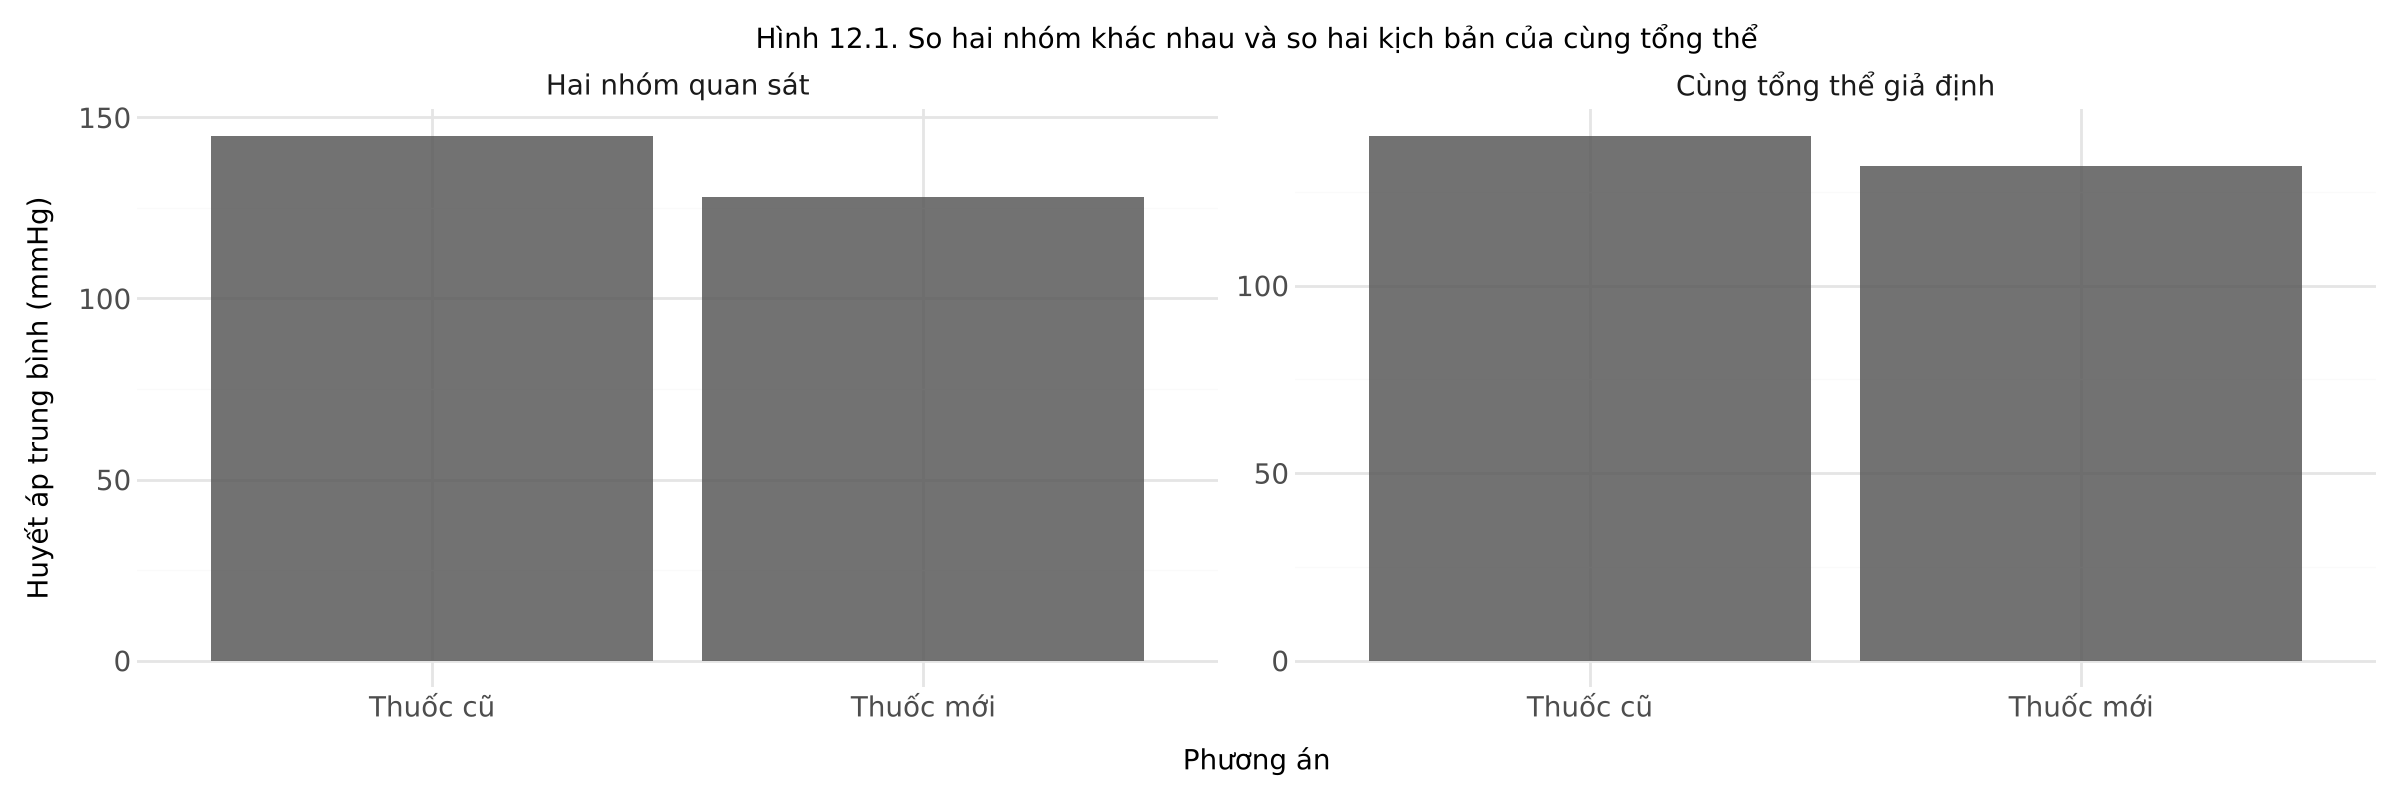

In [3]:
plot_data = comparison.copy()
plot_data['scenario'] = pd.Categorical(plot_data['scenario'], categories=list(pd.unique(plot_data['scenario'])), ordered=True)
p = (ggplot(plot_data, aes(x='condition', y='mean_bp'))
     + geom_col(position='dodge', alpha=0.85)
     + facet_wrap('~scenario', scales='free', ncol=3)
     + labs(title='Hình 12.1. So hai nhóm khác nhau và so hai kịch bản của cùng tổng thể', x='Phương án', y='Huyết áp trung bình (mmHg)')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(comparison['scenario'].nunique()/3)))), text=element_text(size=10)))
display(p)

Ô bên phải không phải dữ liệu thật: không ai quan sát được cùng một nhóm người dưới cả hai thuốc cùng lúc. Phần còn lại của buổi học tìm cách **ước lượng** ô bên phải từ dữ liệu kiểu ô bên trái, và nói rõ cần giả định gì để làm được việc đó.

<a id="muc-2"></a>

## 2. Một cá thể, hai kết quả tiềm năng nhưng chỉ một kết quả quan sát

### Kết quả tiềm năng

Một bệnh nhân dùng thuốc mới, sau 3 tháng huyết áp là 130 mmHg. **Nếu** chính bệnh nhân đó dùng thuốc cũ thì huyết áp sẽ là bao nhiêu?

Để nói về câu hỏi này cho chính xác, gán cho mỗi cá thể $i$ **hai** kết quả:

- $Y_i(1)$: kết quả nếu cá thể $i$ nhận can thiệp (thuốc mới);
- $Y_i(0)$: kết quả nếu cá thể $i$ nhận đối chứng (thuốc cũ).

Hai số này gọi là **kết quả tiềm năng** (potential outcomes). **Tác động nhân quả cá nhân** là
$$\tau_i=Y_i(1)-Y_i(0).$$
Đọc là: mức thay đổi mà riêng can thiệp gây ra cho riêng cá thể $i$.

### Chỉ thấy được một trong hai

Gọi $Z_i$ là can thiệp cá thể $i$ thực sự nhận. Kết quả ta đo được là kết quả tiềm năng ứng với can thiệp đó:
$$Y_i=Z_i\, Y_i(1)+(1-Z_i)\, Y_i(0).$$
Đọc là: nếu $Z_i=1$ thì $Y_i=Y_i(1)$; nếu $Z_i=0$ thì $Y_i=Y_i(0)$. Giả định này có tên **consistency** (nhất quán).

Kết quả tiềm năng còn lại, ứng với can thiệp **không** được nhận, gọi là **phản thực** (counterfactual). Nó không bao giờ có trong dữ liệu: bệnh nhân không thể quay lại 3 tháng trước để dùng thuốc kia. Đây gọi là **vấn đề cơ bản của suy luận nhân quả**. Nó không phải do đo thiếu chính xác hay thiếu dữ liệu; thu bao nhiêu dữ liệu thì mỗi người vẫn chỉ sống một kịch bản.

Vì vậy ta **không** tính được $\tau_i$ cho từng người. Điều ta có thể làm, với thiết kế và giả định phù hợp, là ước lượng các **trung bình** của $\tau_i$ trên một nhóm người.

### Ví dụ 2 — Giá trị phản thực

Bệnh nhân X dùng thuốc mới, huyết áp đo sau 3 tháng là 130 mmHg. Xác định kết quả quan sát được, kết quả phản thực, và giải thích vì sao chưa tính được tác động cá nhân $\tau_X$. Nêu một ví dụ tương tự trong nông nghiệp.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Quan sát được:* $Z_X=1$, nên $Y_X=Y_X(1)=130$ mmHg.

*Phản thực:* $Y_X(0)$, huyết áp của **chính bệnh nhân X** nếu dùng thuốc cũ. Không quan sát được.

*Tác động cá nhân:* $\tau_X=130-Y_X(0)$ có một ẩn số, nên không tính được từ dữ liệu của riêng X. Lấy huyết áp của một bệnh nhân khác dùng thuốc cũ thay vào cũng không được, vì người đó có thể khác X ở nhiều mặt.

*Ví dụ tương tự:* một thửa ruộng trồng giống mới cho 6,2 tấn/ha. Năng suất của **chính thửa đó** nếu trồng giống cũ, cùng mùa vụ ấy, là phản thực.

</details>

Ô dưới lập lại bảng của slide (trang 19): sáu bệnh nhân, mỗi người chỉ có **một** trong hai cột $Y(1)$, $Y(0)$; ô còn lại hiện "?". Cột $\tau$ trống hết. `style.format(na_rep='?')` chỉ là cách hiển thị giá trị thiếu.

In [4]:
observed_only=pd.DataFrame({'Bệnh nhân':['X','B','C','D','E','F'],'Z':[1,0,1,0,1,0],
    'Y(1)':[130,np.nan,125,np.nan,138,np.nan],
    'Y(0)':[np.nan,142,np.nan,150,np.nan,135], 'τ':[np.nan]*6})
display(observed_only.style.format(na_rep='?',precision=0).set_caption('Mỗi người thiếu một kết quả tiềm năng'))
print('Không điền ? bằng trung bình nhóm rồi coi đó là phản thực đã biết.')

,Bệnh nhân,Z,Y(1),Y(0),τ
0,X,1,130,?,?
1,B,0,?,142,?
2,C,1,125,?,?
3,D,0,?,150,?
4,E,1,138,?,?
5,F,0,?,135,?


Không điền ? bằng trung bình nhóm rồi coi đó là phản thực đã biết.


Các ô "?" ở đây khác dữ liệu thiếu thông thường (người quên trả lời, máy đo hỏng). Chúng thiếu **theo định nghĩa**: đúng một nửa số ô luôn thiếu, và việc ô nào thiếu do chính cơ chế chọn thuốc quyết định. Điền trung bình nhóm vào rồi coi như đã biết phản thực là đang **giả định** sẵn điều cần chứng minh.

<a id="muc-3"></a>

## 3. ATE, ATT, ATC nhắm tới nhóm nào?

Không tính được $\tau_i$, nhưng ta có thể nói về trung bình của nó trên một nhóm người. Ba trung bình hay dùng:

$$\text{ATE}=E[Y(1)-Y(0)],\qquad \text{ATT}=E[Y(1)-Y(0)\mid Z=1],\qquad \text{ATC}=E[Y(1)-Y(0)\mid Z=0].$$

| Đại lượng | Tên đầy đủ | Lấy trung bình trên | Câu hỏi tương ứng |
|---|---|---|---|
| ATE | Average Treatment Effect | toàn bộ tổng thể mục tiêu | nếu **cả** tổng thể chuyển từ cũ sang mới thì sao? |
| ATT | Average Treatment effect on the Treated | những người **đã** nhận can thiệp | thuốc mới có giúp **những người đang dùng nó** không? |
| ATC | Average Treatment effect on the Controls | những người **chưa** nhận | nếu mở rộng thuốc mới cho **những người đang dùng thuốc cũ** thì sao? |

### Quan hệ giữa ba đại lượng

$$\text{ATE}=P(Z=1)\cdot\text{ATT}+P(Z=0)\cdot\text{ATC}.$$
Đọc là: ATE là trung bình có trọng số của ATT và ATC, trọng số là tỉ lệ mỗi nhóm.

**Khi nào ATT khác ATE?** Khi tác động cá nhân **không đồng nhất** và khác nhau **có hệ thống** giữa người nhận và người không nhận. Chỉ riêng việc nhóm nhận "không đại diện" chưa đủ: nếu mọi người có cùng tác động $-8$, thì ATT = ATC = ATE = $-8$ dù nhóm nhận toàn người già.

Khi can thiệp được **gán ngẫu nhiên**, độc lập với kết quả tiềm năng, thì ATE = ATT = ATC ở mức tổng thể. Một mẫu hữu hạn cụ thể vẫn có thể cho ba ước lượng hơi khác nhau do ngẫu nhiên.
<details><summary><b>Vì sao?</b> ATE là trung bình có trọng số của ATT và ATC</summary>

Đặt $\tau=Y(1)-Y(0)$. Theo công thức kỳ vọng toàn phần, chia tổng thể theo $Z$:
$$E(\tau)=P(Z=1)\, E(\tau\mid Z=1)+P(Z=0)\, E(\tau\mid Z=0).$$
Ba kỳ vọng lần lượt là ATE, ATT, ATC. $\blacksquare$

Đây chỉ là việc tính trung bình của cả tổng thể bằng cách tính trung bình từng phần rồi gộp theo tỉ lệ, giống tính điểm trung bình cả lớp từ điểm trung bình hai nhóm.

</details>

### Câu hỏi 1 — Tính ATE, ATT, ATC từ bảng kết quả tiềm năng

Bảng giả định dưới đây cho biết **cả hai** kết quả tiềm năng (huyết áp, mmHg) của 5 cá thể: dưới thuốc mới $Y(1)$ và thuốc cũ $Y(0)$; $Z$ là thuốc thực nhận (1 = mới).

| $i$ | $Y(1)$ | $Y(0)$ | $Z$ |
|---|---:|---:|---:|
| 1 | 130 | 140 | 1 |
| 2 | 125 | 138 | 0 |
| 3 | 150 | 150 | 1 |
| 4 | 118 | 130 | 0 |
| 5 | 135 | 142 | 1 |

Tính ATE, ATT (trung bình trên nhóm $Z=1$), ATC (trên nhóm $Z=0$), rồi kiểm tra ATE $=P(Z=1)\,$ATT $+\ P(Z=0)\,$ATC.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1: tác động từng người.* $\tau_i=Y_i(1)-Y_i(0)$:

| $i$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $\tau_i$ | $-10$ | $-13$ | $0$ | $-12$ | $-7$ |

*Bước 2: ATE (cả 5 người).*
$$\text{ATE}=\frac{-10-13+0-12-7}5=\frac{-42}5=-8{,}4\text{ mmHg}.$$

*Bước 3: ATT (người 1, 3, 5 có $Z=1$).*
$$\text{ATT}=\frac{-10+0-7}3=-\frac{17}3\approx-5{,}67\text{ mmHg}.$$

*Bước 4: ATC (người 2, 4 có $Z=0$).*
$$\text{ATC}=\frac{-13-12}2=-12{,}5\text{ mmHg}.$$

*Bước 5: kiểm tra.* $P(Z=1)=3/5=0{,}6$, $P(Z=0)=0{,}4$:
$$0{,}6\Big(-\frac{17}3\Big)+0{,}4(-12{,}5)=-3{,}4-5{,}0=-8{,}4.\ \checkmark$$

Trong bảng này, thuốc mới giúp nhóm chưa dùng nó ($-12{,}5$) nhiều hơn nhóm đang dùng ($-5{,}67$). Bảng có cả hai cột là giả định để học; trong nghiên cứu thật, mỗi hàng chỉ có một cột.

</details>

Ô dưới kiểm tra Câu hỏi 1 và thêm một cột: `observed`, kết quả **quan sát được** của từng người theo $Z$. Từ cột này ta tính **hiệu thô**: trung bình nhóm $Z=1$ trừ trung bình nhóm $Z=0$, đúng cái mà một nhà nghiên cứu thật tính được.

**Bạn đoán trước:** hiệu thô có bằng ATE, ATT hay ATC không? Có cùng dấu không?

In [5]:
potential=pd.DataFrame({'id':[1,2,3,4,5],'y1':[130,125,150,118,135],
                        'y0':[140,138,150,130,142],'z':[1,0,1,0,1]})
potential['tau']=potential.y1-potential.y0
potential['observed']=np.where(potential.z==1,potential.y1,potential.y0)
ate=potential.tau.mean()
att=potential.loc[potential.z==1,'tau'].mean()
atc=potential.loc[potential.z==0,'tau'].mean()
display(potential)
print('ATE, ATT, ATC:',ate,att,atc)
print('Hiệu thô quan sát:',potential.loc[potential.z==1,'observed'].mean()-potential.loc[potential.z==0,'observed'].mean())
assert np.isclose(ate,potential.z.mean()*att+(1-potential.z.mean())*atc)

,id,y1,y0,z,tau,observed
0,1,130,140,1,-10,130
1,2,125,138,0,-13,138
2,3,150,150,1,0,150
3,4,118,130,0,-12,130
4,5,135,142,1,-7,135


ATE, ATT, ATC: -8.4 -5.666666666666667 -12.5
Hiệu thô quan sát: 4.333333333333343


**Kết quả.** Hiệu thô là $\frac{130+150+135}3-\frac{138+130}2=138{,}33-134=+4{,}33$ mmHg: **dương**, trong khi mọi tác động trung bình đều âm. Người đọc chỉ có cột `observed` sẽ kết luận thuốc mới làm **tăng** huyết áp.

Nguyên nhân: nhóm được kê thuốc mới (người 1, 3, 5) vốn có huyết áp cao hơn. Nếu cả hai nhóm cùng dùng thuốc cũ, nhóm $Z=1$ có trung bình $Y(0)$ là $(140+150+142)/3=144$, nhóm $Z=0$ là $(138+130)/2=134$: chênh 10 mmHg **trước khi thuốc làm gì cả**.
<details><summary><b>Vì sao?</b> hiệu thô = ATT + chệch chọn</summary>

Theo consistency, trong nhóm $Z=1$ ta thấy $Y(1)$, trong nhóm $Z=0$ ta thấy $Y(0)$. Thêm bớt $E[Y(0)\mid Z=1]$:
$$\underbrace{E[Y\mid Z=1]-E[Y\mid Z=0]}_{\text{hiệu thô}}
=\underbrace{E[Y(1)-Y(0)\mid Z=1]}_{\text{ATT}}
+\underbrace{E[Y(0)\mid Z=1]-E[Y(0)\mid Z=0]}_{\text{chệch chọn}}.$$
Số hạng cuối so hai nhóm **trong cùng kịch bản thuốc cũ**: nó đo hai nhóm vốn khác nhau bao nhiêu khi chưa có tác động nào. Với bảng trên: $+4{,}33=-5{,}67+10$.

Hiệu thô bằng ATT khi và chỉ khi chệch chọn bằng 0, tức hai nhóm có cùng $Y(0)$ trung bình. Gán ngẫu nhiên làm điều đó đúng (mục 6). Dữ liệu quan sát thì không có gì bảo đảm.

</details>

### Ví dụ 3 — Chênh lệch tỉ lệ quan sát

Bảng `grad_job` (bộ dữ liệu tổng hợp của STAT 20, dùng để minh họa) có 20 sinh viên tốt nghiệp; biến `cal_grad` cho biết tốt nghiệp UC Berkeley hay không, `good_job` cho biết có việc làm tốt không; ngoài ra có `GPA`, `years_exp` (số năm kinh nghiệm), `rec` (thư giới thiệu). Tính tỉ lệ có việc tốt theo từng nhóm `cal_grad` và chênh lệch. Chênh lệch đó có tự động là tác động nhân quả của việc học ở UC Berkeley không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Tính.* Nhóm `cal_grad = True`: 5/5 có việc tốt, tỉ lệ 1,000. Nhóm `False`: 10/15, tỉ lệ $\approx0{,}667$. Chênh lệch:
$$\bar Y_{Z=1}-\bar Y_{Z=0}=1{,}000-0{,}667=0{,}333,$$
tức nhóm tốt nghiệp UC Berkeley có tỉ lệ việc tốt cao hơn khoảng 33,3 điểm phần trăm.

*Diễn giải.* Đây là **chênh lệch quan sát**. Sinh viên không được gán ngẫu nhiên vào trường; GPA, kinh nghiệm, thư giới thiệu, hoàn cảnh gia đình... có thể khác giữa hai nhóm và đều có thể ảnh hưởng đến việc làm. Chưa loại trừ được những khác biệt đó thì chưa coi 0,333 là ước lượng tác động.

Bảng là dữ liệu tổng hợp dùng để giảng dạy, không phải bằng chứng về cựu sinh viên thật; chỉ có 5 người trong nhóm `True`.

</details>

In [6]:
grad_job=pd.read_csv(DATA/'grad_job.csv')
display(grad_job.head())
rates=grad_job.assign(good_job_num=grad_job.good_job.eq('yes')).groupby('cal_grad').good_job_num.agg(['count','mean','sum'])
display(rates)
print('Hiệu quan sát:',rates.loc[True,'mean']-rates.loc[False,'mean'])

,id,GPA,years_exp,rec,cal_grad,good_job
0,1,3.73,3,moderate,False,yes
1,2,3.36,0,moderate,False,no
2,3,3.25,1,strong,False,yes
3,4,3.19,0,moderate,True,yes
4,5,2.66,3,weak,False,yes


,count,mean,sum
cal_grad,,,
False,15,0.66667,10
True,5,1.00000,5


Hiệu quan sát: 0.33333333333333337


`grad_job.good_job.eq('yes')` đổi cột chữ "yes"/"no" thành True/False; trung bình của cột True/False là tỉ lệ True. `.agg(['count', 'mean', 'sum'])` cho số người, tỉ lệ, và số người có việc tốt trong mỗi nhóm.

Trong bảng này, nhóm `False` có GPA trung bình khoảng 3,36 và 1,7 năm kinh nghiệm; nhóm `True` có 3,19 và 1,2 năm. GPA và kinh nghiệm là **biến nền**: chúng có trước khi đi làm và có thể ảnh hưởng cả hai phía. Tuần 13 sẽ ghép cặp những sinh viên giống nhau về các biến này để so sánh công bằng hơn, nhưng vẫn không loại được những khác biệt **không đo**.

### Câu hỏi 2 — Ước lượng ATE từ dữ liệu giả định

20 người được phân ngẫu nhiên thành hai nhóm bằng nhau; giả sử mọi người tuân thủ phương pháp được phân và không ảnh hưởng đến kết quả của nhau (SUTVA). 10 người dùng app học từ vựng mới đạt điểm trung bình 82; 10 người dùng cách học cũ đạt 74. Tính ước lượng ATE và viết một câu diễn giải đúng nghĩa (không khẳng định chắc chắn cho một cá nhân cụ thể).

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Ước lượng.*
$$\widehat{\text{ATE}}=\bar Y_{\text{app mới}}-\bar Y_{\text{cách cũ}}=82-74=8\text{ điểm}.$$

*Vì sao được dùng hiệu thô?* Vì phân nhóm ngẫu nhiên: khi đó chệch chọn bằng 0 ở mức kỳ vọng (mục 6), nên hiệu hai trung bình ước lượng không chệch cho ATE.

*Diễn giải.* Với thiết kế ngẫu nhiên hóa đã nêu, 8 điểm là ước lượng tác động trung bình của app mới so với cách học cũ, đối với nhóm đối tượng nghiên cứu.

*Không được nói:* "ai dùng app mới cũng tăng đúng 8 điểm", hay "app tăng 8 điểm cho mọi người học". Ước lượng vẫn có sai số ngẫu nhiên (chỉ 20 người; một lần phân nhóm khác có thể cho 5 hay 11 điểm), và tác động có thể khác nhau giữa các cá nhân.

</details>

### ATE là một con số trung bình

Đúng: "ATE $=-8$ mmHg" nghĩa là nếu **toàn bộ tổng thể** chuyển từ thuốc cũ sang thuốc mới, huyết áp **trung bình** kỳ vọng giảm 8 mmHg (với điều kiện các giả định ở mục 4 thỏa).

Sai: "bệnh nhân nào dùng thuốc mới cũng giảm chắc chắn 8 mmHg". Tác động có thể khác nhau giữa các cá thể (**không đồng nhất**); ATE có thể che khuất điều đó. Cũng vậy, "ATE của phân bón mới là +0,8 tấn/ha" là mức tăng trung bình trên các ruộng khảo sát, không phải mức tăng chắc chắn của từng thửa.

Trường hợp cực đoan: các tác động trái dấu có thể triệt tiêu nhau, cho ATE $\approx0$ dù **mọi người** đều bị tác động. Ô dưới mô phỏng hai tổng thể 3.000 người mà ta biết $\tau_i$ của từng người:

- tổng thể 1: $\tau_i\sim\mathcal N(-8;\ 5^2)$;
- tổng thể 2: một nửa có $\tau_i\approx-15$, nửa kia $\tau_i\approx+15$.

In [7]:
r_effect=np.random.default_rng(42)
tau_var=r_effect.normal(-8,5,3000)
tau_cancel=np.r_[r_effect.normal(-15,3,1500),r_effect.normal(15,3,1500)]
effect_plot=pd.concat([pd.DataFrame({'tau':v,'scenario':name}) for name,v in
    [('Tâm gần −8 mmHg',tau_var),('Hai tác động trái dấu',tau_cancel)]])
display(effect_plot.groupby('scenario').tau.agg(['mean','std']))

,mean,std
scenario,,
Hai tác động trái dấu,0.02633,15.31468
Tâm gần −8 mmHg,-8.12761,5.03830


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(effect_plot, aes(...))` lấy bảng `effect_plot`; trong `aes`, trục ngang là cột `tau`. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `0`. `facet_wrap('~scenario', scales='free')` vẽ mỗi giá trị của `scenario` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Ô “Tâm gần −8 mmHg”: tác động rải quanh −8, phần lớn âm, vài người dương. Ô “Hai tác động trái dấu”: hai đống tách hẳn nhau ở −15 và +15, gần như **không ai** ở 0, dù trung bình (bảng in ra) chỉ khoảng 0,03. Đường đứt đoạn là 0.

<!-- branch-plot-instructions: end -->

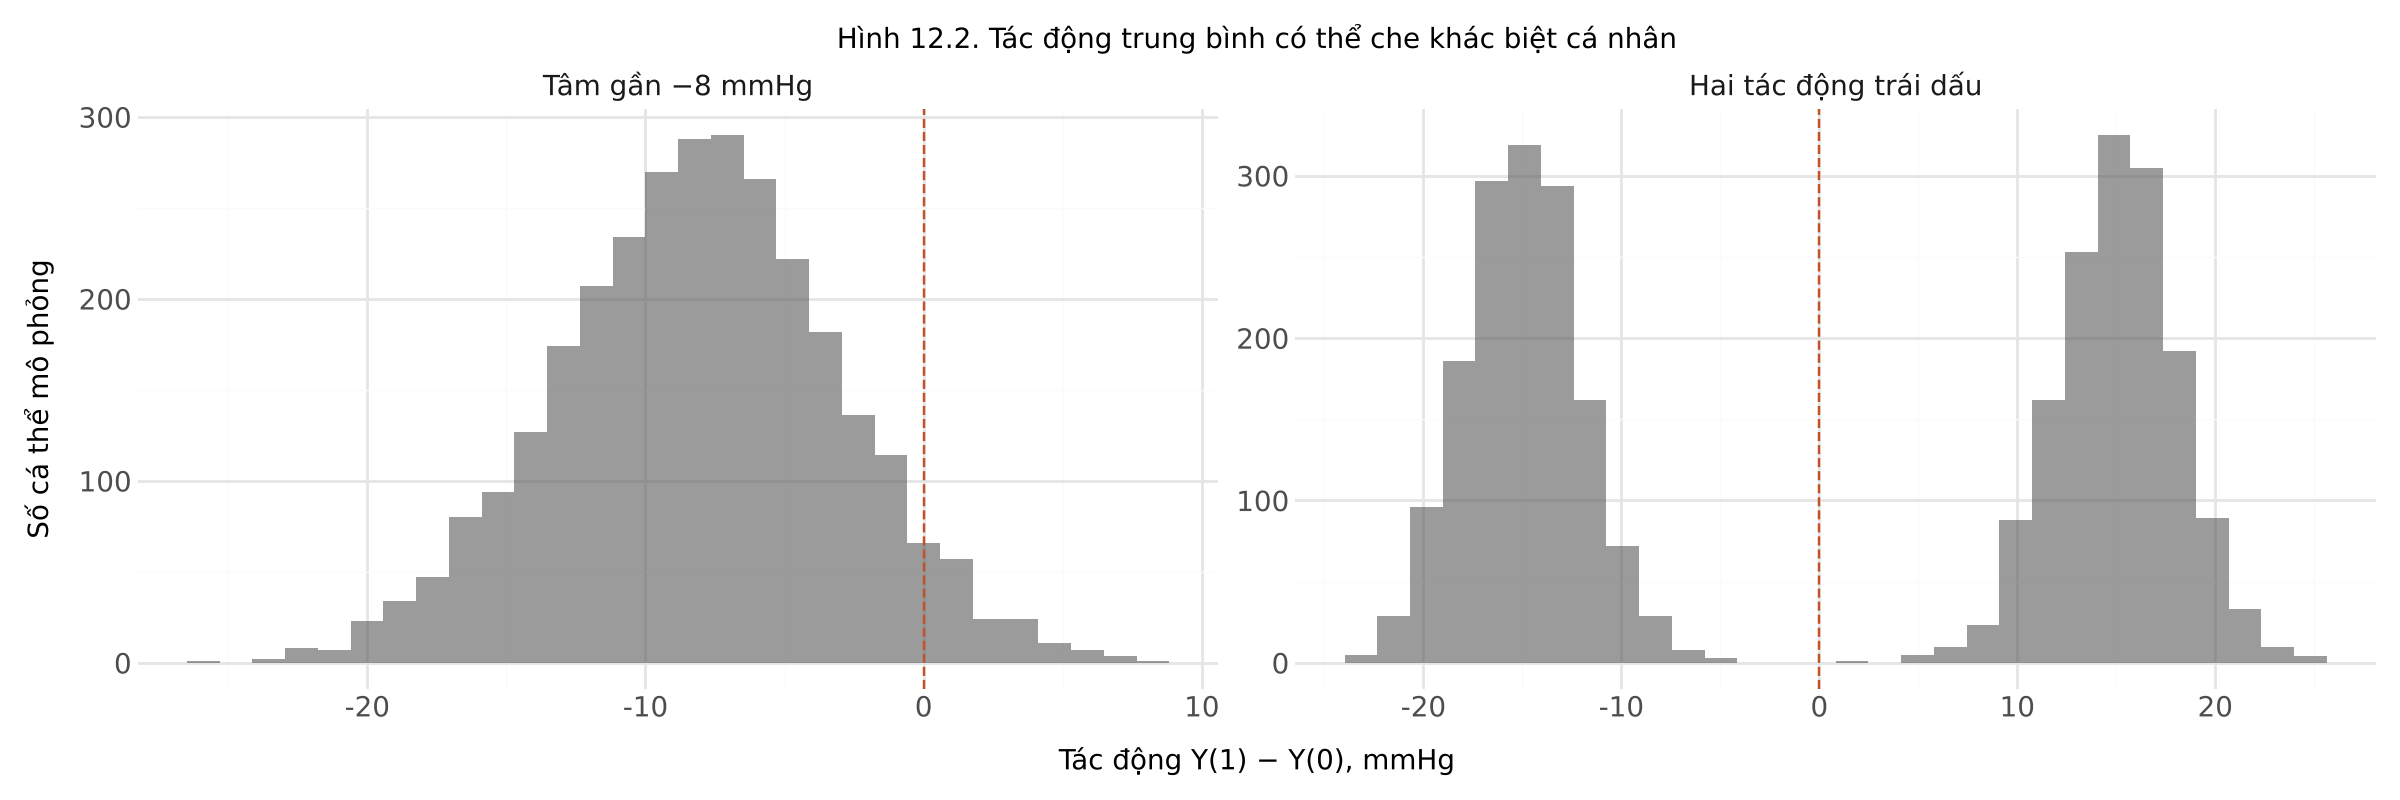

In [8]:
plot_data = effect_plot.copy()
plot_data['scenario'] = pd.Categorical(plot_data['scenario'], categories=list(pd.unique(plot_data['scenario'])), ordered=True)
p = (ggplot(plot_data, aes(x='tau'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=0, linetype='dashed', color='#C4512A')
     + facet_wrap('~scenario', scales='free', ncol=3)
     + labs(title='Hình 12.2. Tác động trung bình có thể che khác biệt cá nhân', x='Tác động Y(1) − Y(0), mmHg', y='Số cá thể mô phỏng')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(effect_plot['scenario'].nunique()/3)))), text=element_text(size=10)))
display(p)

Ở ô bên phải, báo cáo "ATE $\approx0$, thuốc không có tác dụng" sẽ che mất việc thuốc giúp một nửa số người và hại nửa kia. Mô phỏng này biết $\tau_i$ của từng người, điều không bao giờ có trong thực tế; ta dùng nó chỉ để hiểu một trung bình có thể giấu những gì.

<a id="muc-4"></a>

## 4. Ba giả định nối dữ liệu với câu hỏi phản thực

Chênh lệch tỉ lệ 0,333 ở Ví dụ 3 tính được từ dữ liệu. Câu hỏi là: **khi nào** một chênh lệch như vậy được dùng làm ước lượng tác động nhân quả? Cần ba giả định.

### Giả định 1 — SUTVA và consistency

SUTVA (Stable Unit Treatment Value Assumption) gồm hai phần:

- **Không giao thoa**: kết quả của cá thể A không phụ thuộc vào can thiệp mà cá thể B nhận.
  - Thỏa: huyết áp của bệnh nhân A không phụ thuộc thuốc bệnh nhân B dùng.
  - Vi phạm: hiệu quả vắc-xin cho một người phụ thuộc vào số người xung quanh đã tiêm (miễn dịch cộng đồng); điểm của một sinh viên dùng app phụ thuộc vào việc bạn cùng nhóm có dùng app không.
- **Không có nhiều phiên bản ngầm** của cùng một can thiệp.
  - Vi phạm: "dùng thuốc mới" thực chất gồm nhiều liều rất khác nhau; khi đó $Y(1)$ không còn là một đại lượng duy nhất.

**Consistency** đi kèm SUTVA: kết quả quan sát đúng bằng kết quả tiềm năng ứng với can thiệp thực nhận, $Y_i=Y_i(Z_i)$.

### Giả định 2 — Ignorability (không có nhiễu ẩn)

$$(Y(1),\ Y(0))\perp Z\mid X.$$
Đọc ký hiệu: $\perp$ là "độc lập", "$\mid X$" là "khi đã biết $X$". Cả dòng: **trong mỗi tầng $X=x$**, cặp kết quả tiềm năng độc lập với việc nhận can thiệp. Nói cách khác, sau khi đã biết các biến nền $X$, việc một người nhận thuốc mới hay cũ không còn liên quan đến kết quả tiềm năng của họ; trong mỗi tầng, hai nhóm có thể so sánh với nhau.

- Thỏa: trong từng mức độ bệnh, việc bác sĩ kê thuốc mới hay cũ chỉ còn do những yếu tố như lịch hẹn, thói quen, không liên quan đến huyết áp sẽ đạt được.
- Vi phạm: bác sĩ chọn thuốc dựa trên một đánh giá trực quan về mức nặng **chưa ghi vào hồ sơ**, mà đánh giá đó liên quan đến kết quả.

Không phải mọi biến ảnh hưởng đến việc chọn can thiệp đều gây vi phạm. Chỉ những biến **chưa đo** và **vẫn liên quan đến kết quả** mới gây vi phạm. Đây là giả định khó kiểm chứng nhất: các biến đã đo cân bằng giữa hai nhóm không chứng minh được rằng các biến chưa đo cũng cân bằng.

### Giả định 3 — Positivity

$$0<P(Z=1\mid X=x)<1\quad\text{với mọi } x \text{ thuộc tổng thể mục tiêu}.$$
Đọc là: trong mọi tầng biến nền, cả hai mức can thiệp đều có cơ hội xảy ra (xác suất khác 0 và khác 1). Có vậy mới có cơ sở so sánh trong từng tầng.

- Thỏa: ở mọi nhóm tuổi đều có cả bệnh nhân dùng thuốc mới lẫn thuốc cũ.
- Vi phạm thật: chính sách không cho một nhóm nhận một trong hai can thiệp (ví dụ chống chỉ định thuốc mới cho phụ nữ mang thai).
- **Chỉ là dấu hiệu, chưa chắc vi phạm**: trong mẫu không thấy ai thuộc nhóm $X=x$ nhận thuốc mới. Có thể do vi phạm thật, có thể chỉ do mẫu nhỏ. Đếm được 0 người trong 100 không chứng minh $P(Z=1\mid X=x)=0$ trong tổng thể.

### Ba giả định trong một nghiên cứu

Nghiên cứu thuốc hạ huyết áp mới ($Z$), kết quả là huyết áp sau 3 tháng ($Y$), biến nền $X$ là mức nặng bệnh ban đầu.

| Giả định | Thỏa | Vi phạm |
|---|---|---|
| SUTVA | thuốc của bệnh nhân này không ảnh hưởng huyết áp bệnh nhân khác | bệnh nhân chia sẻ thuốc cho nhau; "thuốc thực nhận" không rõ |
| Ignorability | trong mỗi mức bệnh, việc kê thuốc nào không còn liên quan đến kết quả | còn yếu tố nặng/nhẹ chưa ghi hồ sơ, vừa ảnh hưởng chọn thuốc vừa ảnh hưởng huyết áp |
| Positivity | mọi mức bệnh đều có người dùng cả hai thuốc | bệnh nhân rất nặng luôn được kê thuốc mới, không có đối chứng |

Ô dưới mô phỏng 1.200 bệnh nhân tuổi 20–85 dưới hai quy tắc kê thuốc:

- **Có chồng lấn**: mỗi người có 50% cơ hội nhận thuốc mới, ở mọi tuổi;
- **Quy định**: người trên 65 tuổi không bao giờ nhận thuốc mới (`np.where(age > 65, 0, .5)`), dưới 65 thì 50%.

Bảng đếm số người theo (trên 65 hay không, thuốc).

In [9]:
r_overlap=np.random.default_rng(42)
age=r_overlap.uniform(20,85,1200)
z_overlap=r_overlap.binomial(1,.5,len(age))
z_rule=r_overlap.binomial(1,np.where(age>65,0,.5))
overlap=pd.concat([pd.DataFrame({'age':age,'z':z.astype(str),'scenario':name}) for name,z in
    [('Có cơ hội nhận cả hai ở mọi tuổi',z_overlap),('Quy định không dùng mới trên 65',z_rule)]])
display(overlap.assign(over65=overlap.age>65).groupby(['scenario','over65','z']).size())

scenario                          over65  z
Có cơ hội nhận cả hai ở mọi tuổi  False   0    438
                                          1    385
                                  True    0    189
                                          1    188
Quy định không dùng mới trên 65   False   0    399
                                          1    424
                                  True    0    377
dtype: int64

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(overlap, aes(...))` lấy bảng `overlap`; trong `aes`, trục ngang là cột `age`. `fill='z'` cho mỗi giá trị của cột `z` một màu riêng; `alpha=0.6` làm cột trong suốt để thấy phần chồng lên nhau. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `65`. `facet_wrap('~scenario', scales='free')` vẽ mỗi giá trị của `scenario` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Màu là thuốc nhận được (`1` = mới, `0` = cũ). Ô trái: hai màu xen nhau trên cả trục tuổi. Ô phải: bên phải đường 65 chỉ còn màu `0`. Trên 65 tuổi không có ai dùng thuốc mới để so sánh, nên dữ liệu không nói được gì về tác động của thuốc mới ở nhóm tuổi đó.

<!-- branch-plot-instructions: end -->

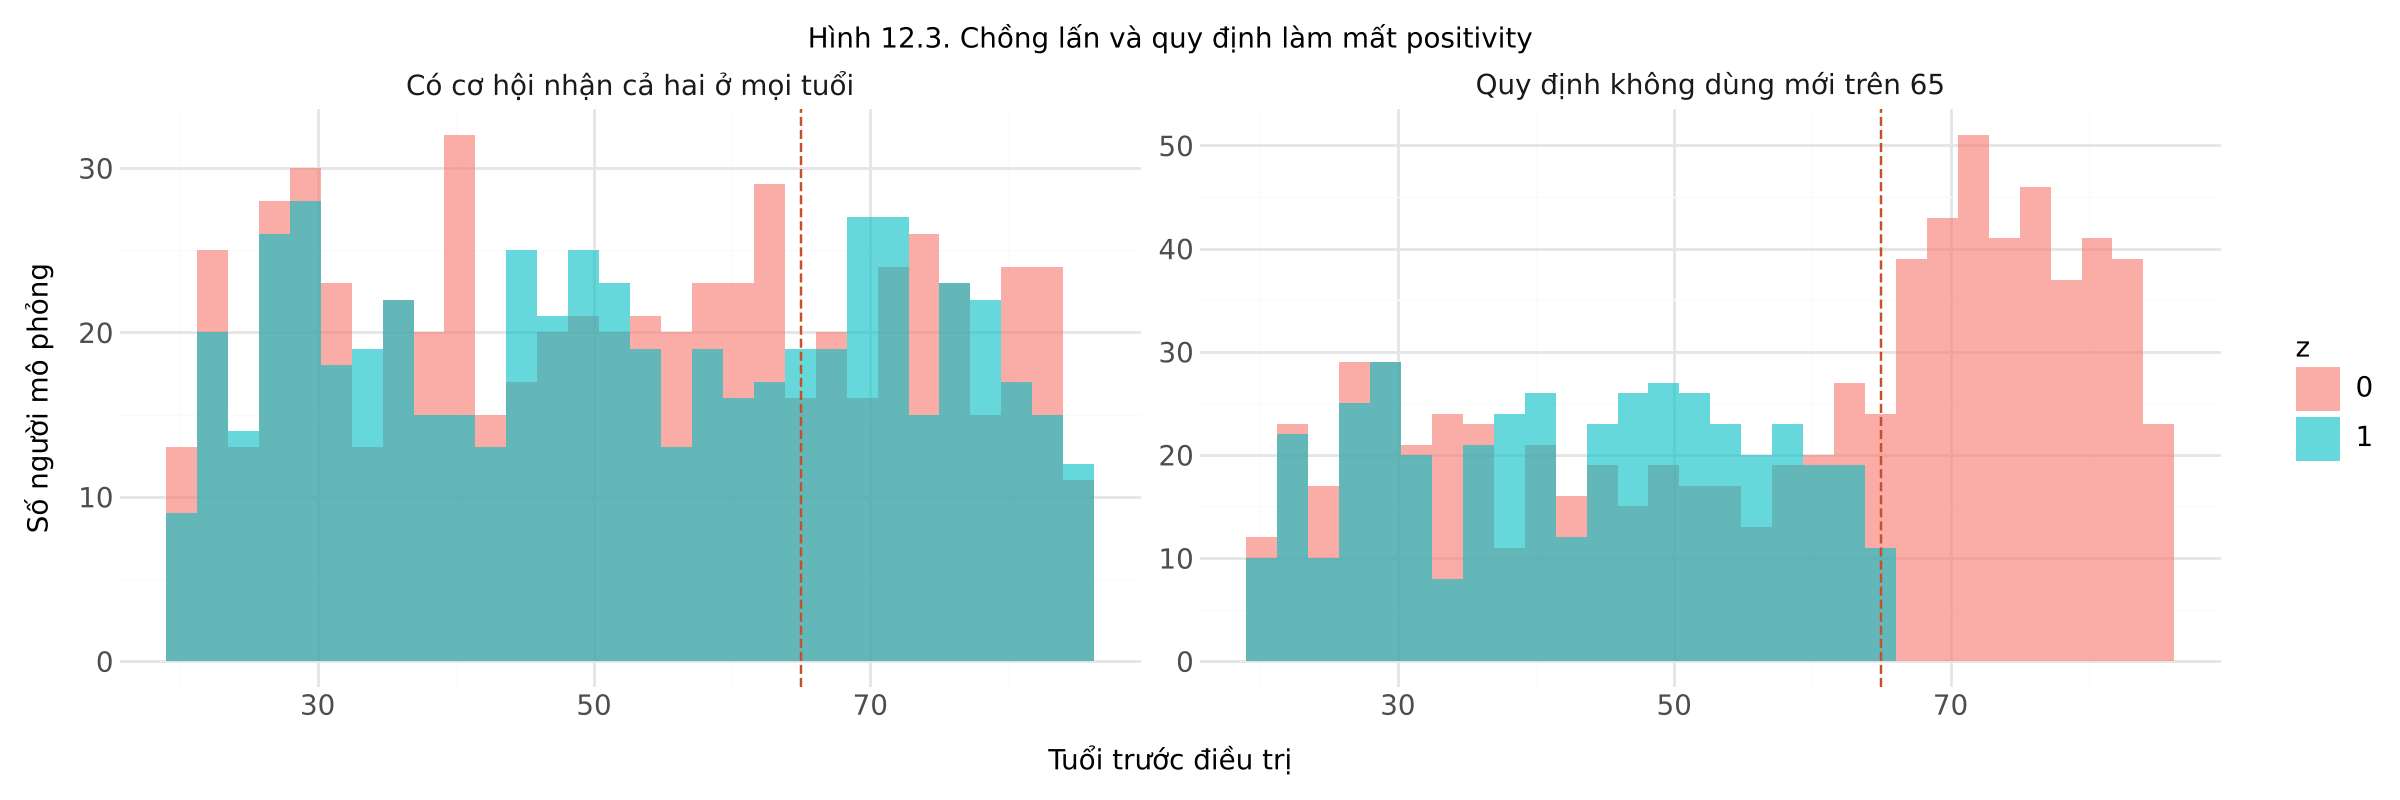

In [10]:
plot_data = overlap.copy()
plot_data['scenario'] = pd.Categorical(plot_data['scenario'], categories=list(pd.unique(plot_data['scenario'])), ordered=True)
p = (ggplot(plot_data, aes(x='age', fill='z'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=65, linetype='dashed', color='#C4512A')
     + facet_wrap('~scenario', scales='free', ncol=3)
     + labs(title='Hình 12.3. Chồng lấn và quy định làm mất positivity', x='Tuổi trước điều trị', y='Số người mô phỏng')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(overlap['scenario'].nunique()/3)))), text=element_text(size=10)))
display(p)

Ở ô phải ta **biết** xác suất nhận thuốc mới trên 65 tuổi bằng 0, vì chính ta viết quy tắc sinh dữ liệu. Trong hồ sơ thật, chỉ thấy ô đếm bằng 0 chưa đủ để kết luận như vậy. Và có chồng lấn tốt như ô trái cũng chưa chứng minh không có nhiễu ẩn: positivity và ignorability là hai giả định riêng.

<a id="muc-5"></a>

## 5. So trong tầng rồi chuẩn hóa theo đúng tổng thể

Nếu ignorability chỉ đúng **sau khi** biết $X$, thì không dùng được hiệu thô. Thay vào đó:

1. So sánh hai can thiệp **trong từng tầng** $X=x$.
2. Gộp các chênh lệch theo tầng, với trọng số là **cơ cấu của tổng thể mục tiêu**.

$$\text{ATE}=\sum_x\Big[E(Y\mid Z=1, X=x)-E(Y\mid Z=0, X=x)\Big]\, P(X=x).$$
Đọc là: trong mỗi tầng, lấy trung bình nhóm mới trừ trung bình nhóm cũ; nhân với tỉ lệ của tầng đó trong tổng thể; cộng lại. Cách làm này gọi là **chuẩn hóa** (standardization).

- Mỗi hiệu trong ngoặc cần có dữ liệu của **cả hai** can thiệp trong tầng đó: đó là lý do cần positivity.
- Trọng số $P(X=x)$ phải là cơ cấu của **tổng thể mục tiêu** đã chọn từ trước, không chọn sau cho kết quả đẹp.
<details><summary><b>Vì sao?</b> công thức chuẩn hóa</summary>

Bắt đầu từ ATE và dùng kỳ vọng toàn phần theo $X$:
$$E[Y(1)]=\sum_x E[Y(1)\mid X=x]\, P(X=x).$$
Theo ignorability, trong tầng $X=x$, $Y(1)$ độc lập với $Z$, nên trung bình của $Y(1)$ trên **cả** tầng bằng trung bình của nó trên **phần nhận** $Z=1$ của tầng:
$$E[Y(1)\mid X=x]=E[Y(1)\mid Z=1, X=x].$$
Theo consistency, với người có $Z=1$ thì $Y(1)=Y$:
$$E[Y(1)\mid Z=1, X=x]=E[Y\mid Z=1, X=x].$$
Positivity bảo đảm trong mỗi tầng có người $Z=1$, nên kỳ vọng có điều kiện này xác định được. Làm tương tự với $Y(0)$ và trừ đi:
$$\text{ATE}=\sum_x\big[E(Y\mid Z=1, X=x)-E(Y\mid Z=0, X=x)\big]P(X=x).\ \blacksquare$$
Mỗi giả định được dùng đúng một lần: ignorability để bỏ điều kiện $Z$, consistency để thay $Y(1)$ bằng $Y$, positivity để kỳ vọng có nghĩa.

</details>

### Ví dụ 4 — Chênh lệch thô gây hiểu lầm

Số liệu giả định (huyết áp trung bình, mmHg):

| Mức bệnh ban đầu | Thuốc mới: $n$ | Huyết áp TB | Thuốc cũ: $n$ | Huyết áp TB |
|---|---|---|---|---|
| Nhẹ | 20 | 120 | 80 | 125 |
| Nặng | 80 | 140 | 20 | 145 |

(1) So sánh thô (gộp hai mức bệnh) cho kết luận gì? (2) So sánh trong từng tầng cho kết luận gì? (3) Chuẩn hóa theo cơ cấu chung của cả 200 người.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1: so sánh thô.* Mỗi nhóm thuốc có 100 người.
$$\bar Y_{\text{mới}}=\frac{20\times120+80\times140}{100}=\frac{2400+11\,200}{100}=136,\qquad \bar Y_{\text{cũ}}=\frac{80\times125+20\times145}{100}=129.$$
Hiệu thô $136-129=+7$ mmHg: có vẻ thuốc mới làm huyết áp **tăng**.

*Câu 2: trong từng tầng.* Nhẹ: $120-125=-5$. Nặng: $140-145=-5$. Ở **cả hai** tầng, thuốc mới thấp hơn 5 mmHg.

*Câu 3: chuẩn hóa.* Cả 200 người có 100 nhẹ và 100 nặng, nên $P(\text{nhẹ})=P(\text{nặng})=0{,}5$:
$$\widehat{\text{ATE}}=0{,}5(-5)+0{,}5(-5)=-5\text{ mmHg}.$$

*Vì sao hiệu thô đổi dấu?* Nhóm thuốc mới có 80% bệnh nặng, nhóm thuốc cũ có 80% bệnh nhẹ. Bệnh nặng vốn có huyết áp cao hơn khoảng 20 mmHg. Hiệu thô vì vậy chủ yếu đo khác biệt **mức bệnh**, không phải khác biệt thuốc. Mức bệnh ban đầu là biến gây nhiễu. Hiện tượng một xu hướng đảo chiều khi gộp các nhóm lại có tên **nghịch lý Simpson**.

Đây là số liệu giả định. Muốn coi $-5$ là tác động thật vẫn cần ba giả định: đặc biệt là không có yếu tố nào khác, ngoài mức bệnh, ảnh hưởng cả việc chọn thuốc lẫn huyết áp.

</details>

In [11]:
strata=pd.DataFrame({'severity':['Nhẹ','Nhẹ','Nặng','Nặng'],
    'drug':['Mới','Cũ','Mới','Cũ'],'n':[20,80,80,20],'mean_bp':[120,125,140,145]})
weighted=strata.assign(total=lambda d:d.n*d.mean_bp).groupby('drug')[['total','n']].sum()
pooled=(weighted.total/weighted.n).rename('mean_bp').reset_index()
pooled['severity']='Gộp'; pooled['n']=100
plot_strata=pd.concat([strata,pooled],ignore_index=True)
display(weighted.assign(mean_bp=weighted.total/weighted.n))
print('Thô mới − cũ:',136-129,'; chuẩn hóa:',.5*(120-125)+.5*(140-145))

,total,n,mean_bp
drug,,,
Cũ,12900,100,129.0
Mới,13600,100,136.0


Thô mới − cũ: 7 ; chuẩn hóa: -5.0


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `aes('severity', 'mean_bp', color='drug', size='n')`: trục ngang là tầng (Nhẹ, Nặng, Gộp), trục đứng là huyết áp trung bình, màu là thuốc, **kích thước chấm** theo số người. `geom_point()` vẽ mỗi dòng của `plot_strata` thành một chấm.

**Đọc hình.** Ở cột Nhẹ và cột Nặng, chấm thuốc mới đều thấp hơn chấm thuốc cũ. Ở cột Gộp, thứ tự đảo ngược. Nhìn kích thước: thuốc mới có chấm to ở Nặng (huyết áp cao), thuốc cũ có chấm to ở Nhẹ (huyết áp thấp); trung bình gộp bị kéo về phía chấm to.

<!-- branch-plot-instructions: end -->

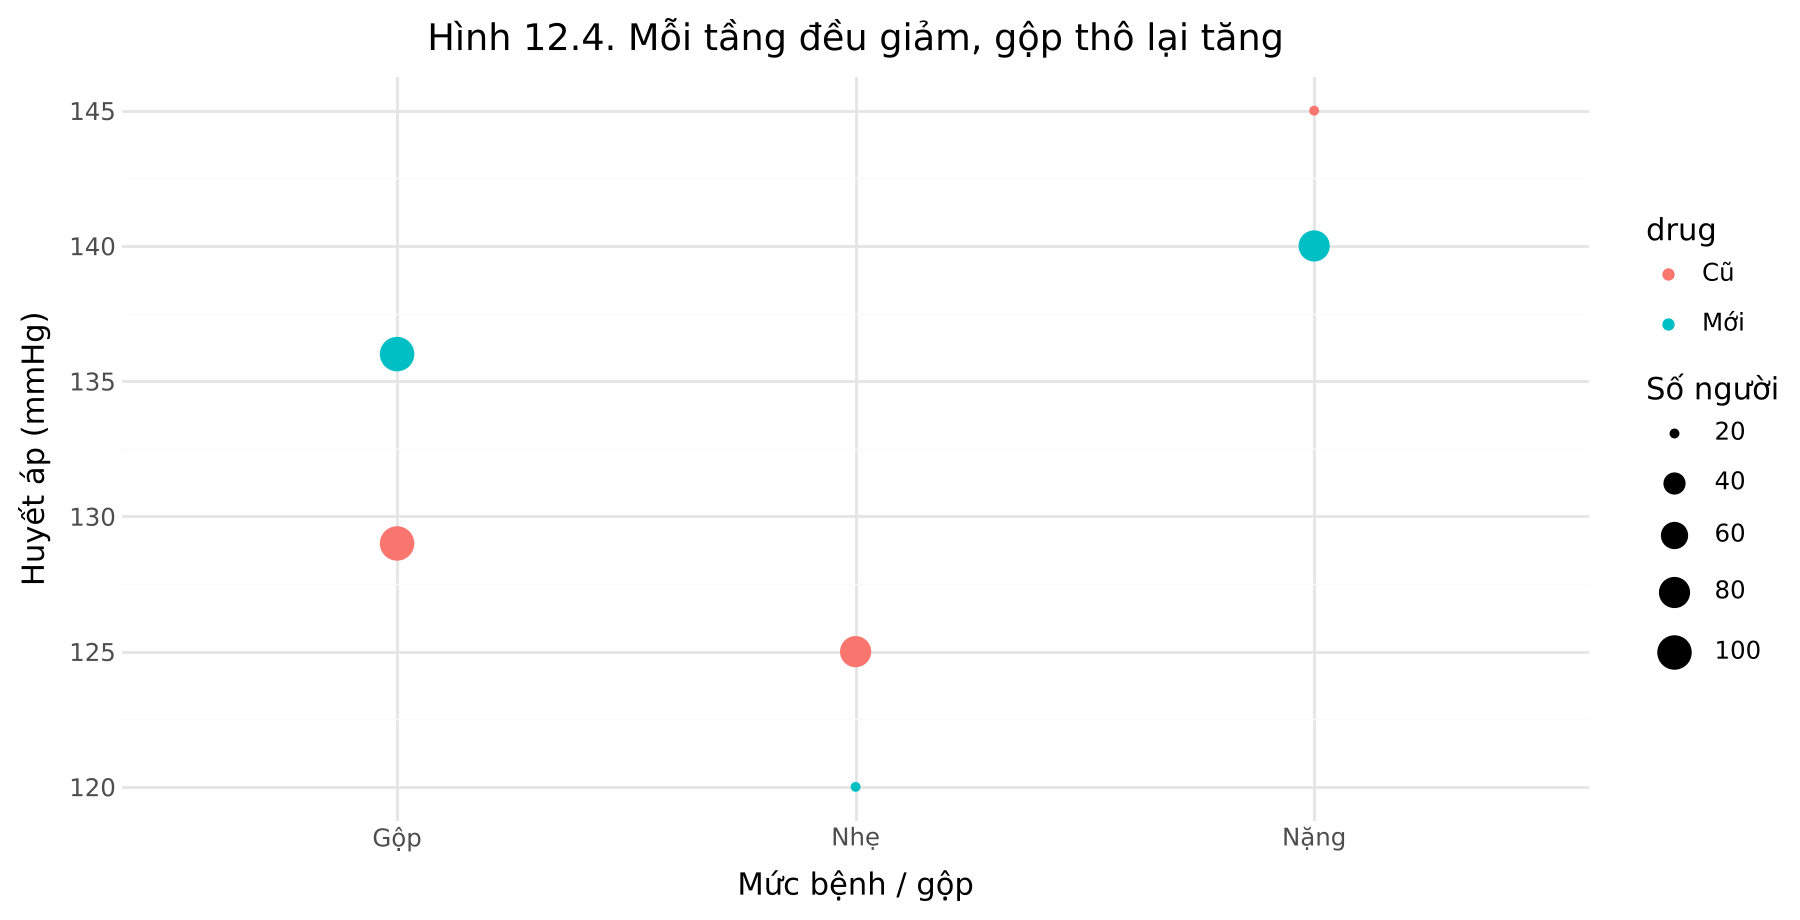

In [12]:
display(ggplot(plot_strata,aes('severity','mean_bp',color='drug',size='n'))
    + geom_point()
    + labs(title='Hình 12.4. Mỗi tầng đều giảm, gộp thô lại tăng',x='Mức bệnh / gộp',y='Huyết áp (mmHg)',size='Số người')
    + theme_minimal()+theme(figure_size=(9,4.6)))

Ở Ví dụ 4, hai tầng có **cùng** hiệu $-5$, nên chọn cơ cấu mục tiêu nào (50/50, 70/30...) cũng ra $-5$. Bài tập dưới có hiệu khác nhau giữa các tầng; khi đó cơ cấu mục tiêu làm thay đổi kết quả.

### Bài tập 1 — Chuẩn hóa theo tầng từ bảng tỉ lệ khỏi

Tỉ lệ khỏi bệnh (số khỏi / số điều trị) theo mức bệnh ban đầu:

| Mức bệnh | Thuốc mới | Thuốc cũ |
|---|---|---|
| Nhẹ | 19/20 | 72/80 |
| Nặng | 48/80 | 10/20 |

(a) Tính tỉ lệ khỏi thô của mỗi thuốc và chênh lệch thô (mới − cũ). (b) Tính chênh lệch trong từng tầng. (c) Chuẩn hóa theo cơ cấu chung (100 ca nhẹ, 100 ca nặng); so dấu với câu a.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(a) Thô.* Mới $=(19+48)/100=0{,}67$; cũ $=(72+10)/100=0{,}82$; chênh lệch thô $=-0{,}15$. Thuốc mới có vẻ kém hơn 15 điểm phần trăm.

*(b) Theo tầng.* Nhẹ: $19/20-72/80=0{,}95-0{,}90=+0{,}05$. Nặng: $48/80-10/20=0{,}60-0{,}50=+0{,}10$. Thuốc mới tốt hơn ở **cả hai** tầng.

*(c) Chuẩn hóa.* $0{,}5(0{,}05)+0{,}5(0{,}10)=+0{,}075$: thuốc mới tốt hơn 7,5 điểm phần trăm.

*So dấu.* Thô âm, chuẩn hóa dương. So sánh thô bị đảo dấu vì thuốc mới chủ yếu được dùng cho ca nặng (80/100), vốn có tỉ lệ khỏi thấp hơn nhiều.

</details>

Ô dưới kiểm tra Bài tập 1. Biến `target_mild` là tỉ lệ ca nhẹ trong **tổng thể mục tiêu**.

**Thử đổi.** Đặt `target_mild = .2` (tổng thể toàn ca nặng hơn) rồi `.8`. Vì hiệu ở tầng nặng (+0,10) lớn hơn tầng nhẹ (+0,05), tổng thể càng nhiều ca nặng thì ATE chuẩn hóa càng lớn, từ +0,09 (20% nhẹ) đến +0,06 (80% nhẹ).

In [13]:
target_mild = .5  # Thử đổi .2, .8; cơ cấu tổng thể mục tiêu
crude=67/100-82/100
diff_mild=19/20-72/80
diff_severe=48/80-10/20
standardized=target_mild*diff_mild+(1-target_mild)*diff_severe
print('Thô:',crude,'; trong tầng:',diff_mild,diff_severe,
      '; chuẩn hóa:',standardized,'=',standardized*100,'điểm phần trăm')
assert np.isclose(diff_mild,.05) and np.isclose(diff_severe,.10)

Thô: -0.1499999999999999 ; trong tầng: 0.04999999999999993 0.09999999999999998 ; chuẩn hóa: 0.07499999999999996 = 7.499999999999996 điểm phần trăm


Câu "ATE là bao nhiêu" chỉ có một đáp án khi đã nói rõ **cho tổng thể nào**. Đừng lẫn cơ cấu của nhóm **thực nhận** thuốc (80% nặng) với cơ cấu của **tổng thể mục tiêu** mà ta muốn kết luận.

### Bài tập 2 — Ba giả định và chuẩn hóa (nâng cao)

Một bệnh viện so sánh thuốc mới ($Z=1$) với thuốc cũ ($Z=0$); kết quả $Y$ là huyết áp sau 3 tháng. Biến nền đã đo là mức nặng bệnh ban đầu $X$ (nhẹ/nặng). (1) Viết điều kiện ignorability theo $X$ bằng ký hiệu, rồi đọc thành lời. (2) Positivity đòi hỏi gì ở tình huống này? Nêu một kịch bản vi phạm. (3) Giả sử cả ba giả định thỏa, viết công thức chuẩn hóa để ước lượng ATE.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(1)* $(Y(1), Y(0))\perp Z\mid X$. Đọc: $\perp$ là độc lập, $\mid X$ là khi đã biết $X$. Trong mỗi mức bệnh, kết quả tiềm năng của một bệnh nhân không liên quan đến việc họ được kê thuốc nào.

*(2)* $0<P(Z=1\mid X=x)<1$ cho cả $x=$ nhẹ và $x=$ nặng: ở mỗi mức bệnh đều có người dùng thuốc mới và người dùng thuốc cũ. Vi phạm nếu, ví dụ, **mọi** bệnh nhân nặng đều được kê thuốc mới: không còn bệnh nhân nặng nào dùng thuốc cũ để so sánh.

*(3)*
$$\widehat{\text{ATE}}=\sum_x\big(\bar Y_{Z=1,\, X=x}-\bar Y_{Z=0,\, X=x}\big)\,\hat P(X=x),$$
với $\hat P(X=x)$ là tỉ lệ của tầng $x$ trong tổng thể mục tiêu.

</details>

<a id="muc-6"></a>

## 6. Bổ sung theo đề cương: vì sao gán ngẫu nhiên giúp ích?

Đề cương tuần 12 có mục thí nghiệm ngẫu nhiên; slide tuần 13 trình bày đầy đủ phần thiết kế. Mục này nối hai tuần bằng một thí nghiệm tính toán.

**Lập luận.** Nếu $Z$ được gán bằng tung đồng xu, độc lập với mọi thứ về con người, thì $Z$ độc lập với $(Y(1), Y(0))$. Khi đó chệch chọn $E[Y(0)\mid Z=1]-E[Y(0)\mid Z=0]$ bằng 0, và hiệu thô bằng ATT, cũng bằng ATE. Ignorability đúng mà **không cần** điều kiện theo $X$ nào, kể cả những biến không đo được.

**Nhưng chỉ đúng ở mức kỳ vọng.** "Không chệch" nghĩa là trung bình qua **rất nhiều** lần gán bằng tác động thật. Một lần gán cụ thể vẫn có thể, do ngẫu nhiên, đặt nhiều người bệnh nặng vào một nhóm hơn. Ngẫu nhiên hóa không bảo đảm cân bằng tuyệt đối trong một mẫu.

**Thiết kế một thí nghiệm** cần nói rõ: đơn vị thí nghiệm, nghiệm thức và đối chứng, biến kết quả, cấp gán ngẫu nhiên, và cùng một quy trình đo cho mọi nhóm. Ngẫu nhiên hóa không sửa được phép đo sai, cũng không tự làm kết quả đại diện cho tổng thể ngoài nghiên cứu.

**Thí nghiệm mô phỏng.** Tổng thể 200 bệnh nhân giả lập, mỗi người có mức bệnh `severity`. Huyết áp nếu dùng thuốc cũ là $Y(0)=140+10\cdot\text{severity}+\text{nhiễu}$; thuốc mới làm giảm đúng 8 mmHg cho mọi người: $Y(1)=Y(0)-8$. Vậy ATE $=-8$, và ta **biết** điều này. So hai cách chọn ai dùng thuốc mới, mỗi cách lặp 2.000 lần:

- **Gán ngẫu nhiên 100–100**: bốc ngẫu nhiên 100 người dùng thuốc mới.
- **Chọn theo mức bệnh**: người càng nặng càng dễ được kê thuốc mới, xác suất $1/(1+e^{-1{,}5\cdot\text{severity}})$.

Mỗi lần tính hiệu thô (trung bình quan sát nhóm mới − nhóm cũ).

**Bạn đoán trước:** cách nào cho các hiệu thô tập trung quanh −8?

In [14]:
# Tổng thể mô phỏng biết cả hai kịch bản để kiểm tra ước lượng.
r_rct=np.random.default_rng(42)
severity=r_rct.normal(0,1,200)
y0=140+10*severity+r_rct.normal(0,3,200)
y1=y0-8
random_est=[]; selected_est=[]
for _ in range(2000):
    z=np.zeros(200,dtype=int); z[r_rct.choice(200,100,replace=False)]=1
    obs=np.where(z==1,y1,y0)
    random_est.append(obs[z==1].mean()-obs[z==0].mean())
    p_assign=1/(1+np.exp(-1.5*severity))
    zs=r_rct.binomial(1,p_assign)
    obs_s=np.where(zs==1,y1,y0)
    selected_est.append(obs_s[zs==1].mean()-obs_s[zs==0].mean())
assignment_plot=pd.concat([pd.DataFrame({'estimate':v,'design':name}) for name,v in
    [('Gán ngẫu nhiên 100–100',random_est),('Chọn theo mức bệnh',selected_est)]])
display(assignment_plot.groupby('design').estimate.agg(['mean','std']))
print('ATE mô phỏng đã biết:',(y1-y0).mean())

,mean,std
design,,
Chọn theo mức bệnh,0.55416,0.90210
Gán ngẫu nhiên 100–100,-7.96669,1.30697


ATE mô phỏng đã biết: -8.0


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(assignment_plot, aes(...))` lấy bảng `assignment_plot`; trong `aes`, trục ngang là cột `estimate`. `fill='design'` cho mỗi giá trị của cột `design` một màu riêng; `alpha=0.6` làm cột trong suốt để thấy phần chồng lên nhau. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `-8`.

**Đọc hình.** Hai histogram, mỗi cái gồm 2.000 hiệu thô. Đường đứt đoạn là ATE thật $=-8$. Histogram “Gán ngẫu nhiên” có tâm đúng ở −8 và trải khoảng ±3. Histogram “Chọn theo mức bệnh” nằm hẳn bên phải, quanh +0,5: gần như mọi lần đều cho kết luận sai rằng thuốc không giúp gì hoặc làm tăng huyết áp.

<!-- branch-plot-instructions: end -->

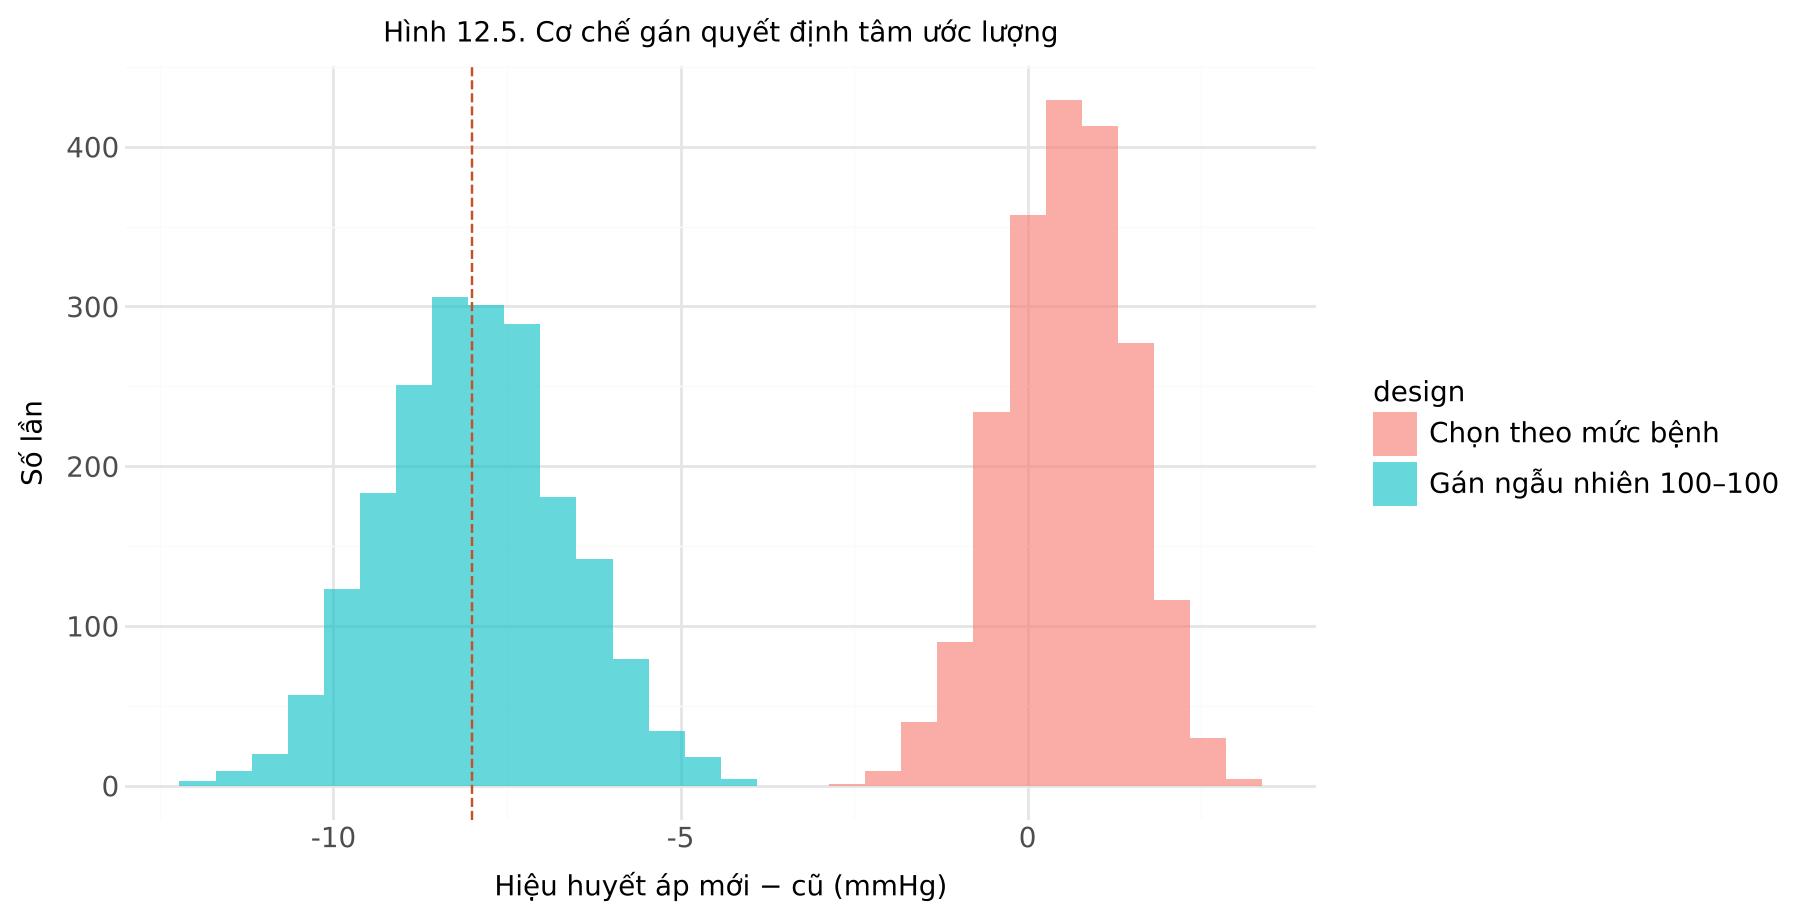

In [15]:
p = (ggplot(assignment_plot, aes(x='estimate', fill='design'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=-8, linetype='dashed', color='#C4512A')
     + labs(title='Hình 12.5. Cơ chế gán quyết định tâm ước lượng', x='Hiệu huyết áp mới − cũ (mmHg)', y='Số lần')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** Gán ngẫu nhiên: trung bình $\approx-7{,}97$, độ lệch chuẩn $\approx1{,}3$. Chọn theo mức bệnh: trung bình $\approx+0{,}55$, lệch khỏi −8 tới 8,5 mmHg; người nặng vừa có huyết áp cao vừa hay được kê thuốc mới, nên chệch chọn gần như triệt tiêu tác động thật.

Hai điểm cần đọc đúng:

- Tăng số lần lặp hay cỡ mẫu không sửa được chệch của cách "chọn theo mức bệnh" (giống Tuần 09: mẫu lớn vẫn có thể tập trung quanh tâm sai).
- Với gán ngẫu nhiên, **từng lần** vẫn dao động: có lần cho −11, có lần cho −5. Ngẫu nhiên hóa bảo đảm tâm đúng, không bảo đảm một thí nghiệm cụ thể cho đúng −8.

Mô phỏng này kiểm tra được lập luận vì ta biết cả $Y(0)$ và $Y(1)$ của mọi người. Nghiên cứu thật không bao giờ có điều đó.

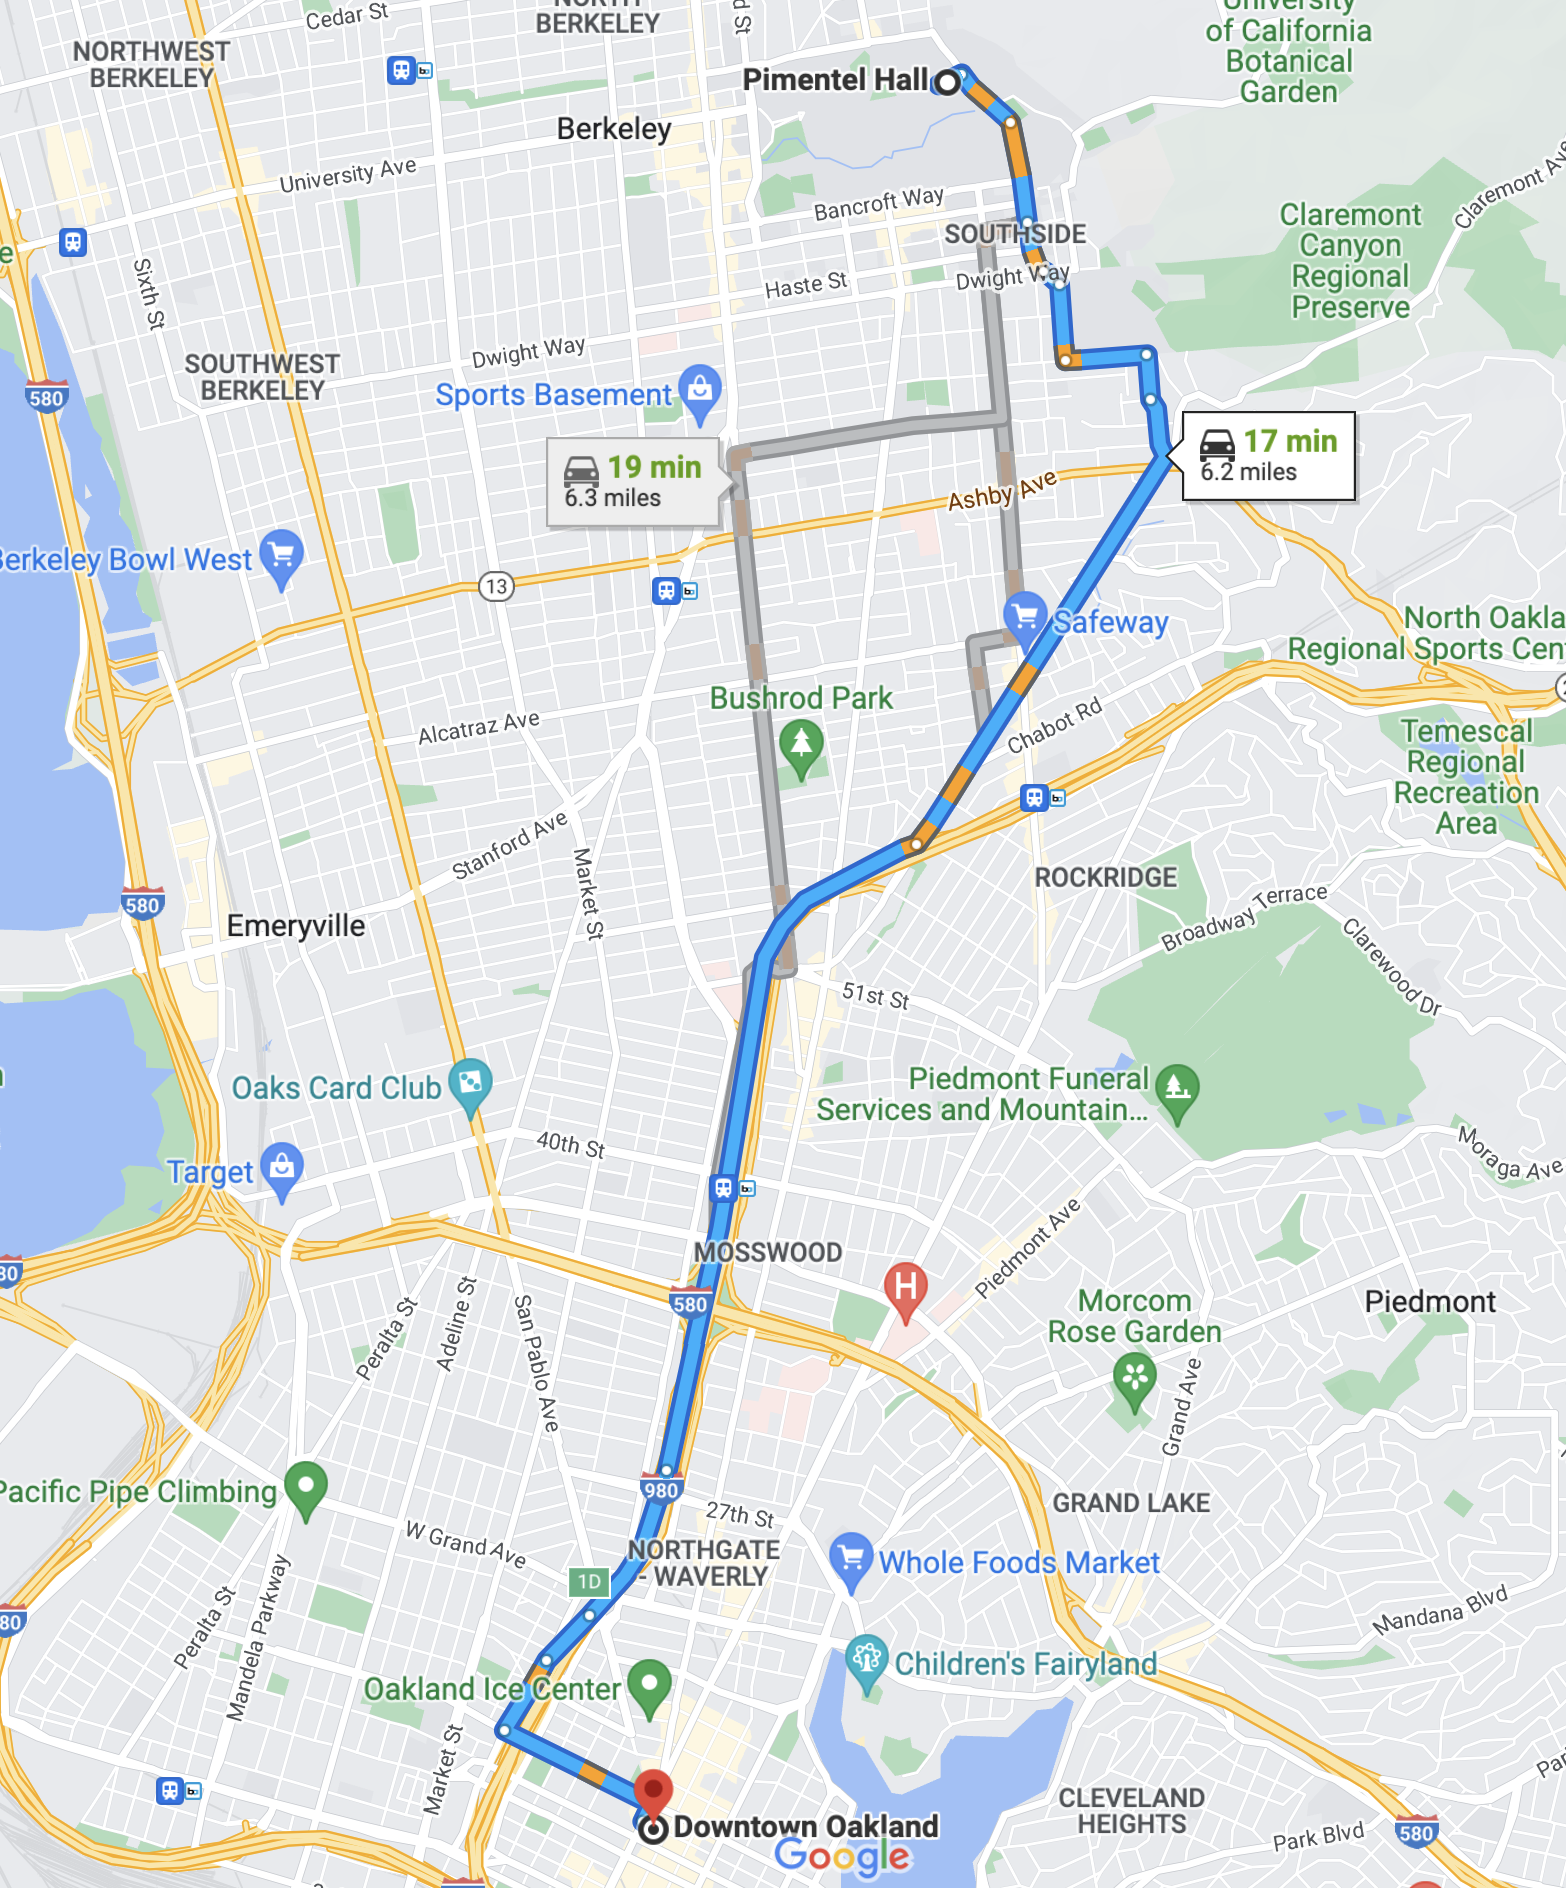

*Hình tham khảo 12.34: Hai tuyến đường trong ví dụ phản thực của STAT 20. Nguồn: STAT 20 bản dịch tiếng Việt, mục 6.1, hình nhúng trong học liệu gốc.*

Đọc thêm mục 6.1: nếu hôm nay bạn đi tuyến A, thời gian của chính chuyến đi ấy nếu đi tuyến B là phản thực. Hôm sau đi thử tuyến B không giải quyết được, vì ngày, giao thông, thời tiết đều đã khác.

## Tóm tắt và lỗi hay gặp

| Ý chính | Lỗi hay gặp |
|---|---|
| Tương quan hỏi “có đi cùng nhau không”; nhân quả hỏi “nếu thay đổi can thiệp thì kết quả có đổi không”. | Đổi chỗ hai vế câu để “kiểm tra” nhân quả. |
| Mỗi cá thể có hai kết quả tiềm năng nhưng chỉ quan sát được một; phản thực không bao giờ có trong dữ liệu. | Lấy kết quả của người khác làm phản thực của một người. |
| Không tính được $\tau_i$; chỉ ước lượng được trung bình: ATE, ATT, ATC. | Diễn giải ATE là tác động của từng người. |
| ATE $=P(Z=1)$ATT $+P(Z=0)$ATC. | Nghĩ ATT ≠ ATE chỉ vì nhóm nhận không đại diện. |
| Hiệu thô = ATT + chệch chọn; chệch chọn có thể đổi cả dấu. | Dùng hiệu thô của dữ liệu quan sát làm ước lượng tác động. |
| Ba giả định: SUTVA (và consistency), ignorability theo $X$, positivity. | Coi cân bằng các biến đã đo là bằng chứng không có nhiễu ẩn. |
| Có biến nhiễu đã đo: so trong tầng rồi chuẩn hóa theo cơ cấu tổng thể mục tiêu. | Chọn trọng số tùy ý; lẫn cơ cấu nhóm nhận với tổng thể mục tiêu. |
| Gán ngẫu nhiên làm chệch chọn bằng 0 ở mức kỳ vọng, kể cả với biến không đo được. | Nghĩ một lần gán ngẫu nhiên bảo đảm hai nhóm giống hệt nhau. |

## Tự kiểm tra và nối sang buổi tiếp theo

1. Một báo cáo nói ATE bằng 0. Điều đó có chứng minh không ai bị can thiệp tác động không? Cho một phản ví dụ.
2. Hai nhóm cân bằng hoàn toàn về tuổi, giới, mức bệnh đã đo. Đã chắc không còn nhiễu ẩn chưa?
3. Với bảng ở Câu hỏi 1, chệch chọn bằng bao nhiêu? Nó có dấu gì và vì sao?
4. Trong Ví dụ 4, nếu tổng thể mục tiêu có 90% ca nhẹ, ATE chuẩn hóa bằng bao nhiêu?

<details><summary>Gợi ý đáp án</summary>

1. Không. Hình 12.2 (ô phải): một nửa có tác động −15, nửa kia +15, trung bình gần 0, nhưng gần như không ai có tác động bằng 0.
2. Chưa. Ignorability nói về **mọi** yếu tố ảnh hưởng cả chọn thuốc và kết quả, kể cả những yếu tố chưa đo (ví dụ đánh giá trực quan của bác sĩ). Cân bằng biến đã đo không kiểm chứng được biến chưa đo.
3. $E[Y(0)\mid Z=1]-E[Y(0)\mid Z=0]=144-134=+10$ mmHg. Dương vì nhóm nhận thuốc mới vốn có huyết áp cao hơn.
4. Vẫn $-5$, vì cả hai tầng có cùng hiệu $-5$.

</details>

**Buổi sau.** Tuần 13 chuyển từ “cần giả định gì để suy luận nhân quả từ dữ liệu quan sát?” sang “nếu chủ động thiết kế thí nghiệm và ngẫu nhiên hóa thì được gì?”. Các khái niệm chính: hiệu lực nội tại và hiệu lực khái quát; đơn vị thí nghiệm và đơn vị quan sát; thí nghiệm ngẫu nhiên có đối chứng (RCT), thiết kế khối và cụm, thử nghiệm A/B; ghép cặp, trước–sau, khác biệt trong khác biệt cho nghiên cứu quan sát.

## Nguồn học liệu

- Slide của học phần: `week12.pdf`; số trang được ghi trong metadata `source_pages` của từng ô.
- Đề cương UET.MAT1052: mục và chuẩn đầu ra của tuần tương ứng.
- STAT 20 bản dịch tiếng Việt: mục 6.1–6.2; ảnh tuyến đường từ 6.1. Các hình tham khảo được nhúng thẳng vào notebook.
- Dữ liệu và cách chuyển đổi: `datasets/W09_W15_SOURCE_MANIFEST.json` và [hướng dẫn tuần 09–15](./README_W09_W15.md). Dữ liệu OpenIntro lấy từ [kho dữ liệu của nhà xuất bản](https://www.openintro.org/data/).